# QuickCare: Deep RL for Emergency Department Resource Scheduling
**CSE 4/546 Final Project Checkpoint, Fall 2026**
Dilip Nallamasa (dilipgou), Harsha Lolabattu (harshaad)

Repo: https://github.com/dilipn444/QuickCare-RL
Board: https://github.com/users/dilipn444/projects/2

A scheduler picks which of four urgency queues gets the next free resource in a simulated ED. We compare FCFS, severity priority, tabular Q-learning and DQN under four scenarios.

## Setup

In [1]:
import csv, json, random
from collections import deque
from pathlib import Path

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
%matplotlib inline

OUT = Path('results')
OUT.mkdir(exist_ok=True)

random.seed(7); np.random.seed(7); torch.manual_seed(7)
torch.set_num_threads(1)
print('numpy', np.__version__, '| torch', torch.__version__)

numpy 2.4.6 | torch 2.11.0+cu130


## Environment
- 100-step shift, 3 service resources, at most one patient starts per step
- 4 urgency classes (critical, urgent, moderate, low), Poisson arrivals, service time 2-5 steps
- state: 4 queue lengths, 4 oldest waits, free resources (9 values); action: which queue to serve
- reward penalises waiting patients (weighted by urgency) and critical/urgent waits over 5 steps
- scenarios change steps 33-65: `surge` (arrivals x1.8), `severity_surge` (critical/urgent x2.5), `shortage` (one resource lost)

In [2]:
SEVERITY = ('critical', 'urgent', 'moderate', 'low')
RATES = np.array([0.10, 0.22, 0.42, 0.62])

class QuickCare:
    """Discrete decision epochs. Arrivals/discharges occur BEFORE each action is selected.

    Each timestep permits at most one service admission, even if several slots are free.
    End-of-horizon waiting cases are counted as backlog, not silently discharged.
    """
    def __init__(self, scenario='normal', horizon=100, slots=3, seed=0):
        if scenario not in {'normal', 'surge', 'severity_surge', 'shortage'}:
            raise ValueError('Unknown scenario')
        if horizon < 3 or slots < 1:
            raise ValueError('Invalid horizon or number of slots')
        self.scenario, self.horizon, self.slots, self.seed = scenario, horizon, slots, seed
        self.action_space_n = 4
        self.reset(seed=seed)

    def reset(self, seed=None, options=None):
        if seed is not None: self.seed = seed
        rng = np.random.default_rng(self.seed)
        rates = np.tile(RATES, (self.horizon, 1))
        start, end = self.horizon // 3, 2 * self.horizon // 3
        if self.scenario == 'surge': rates[start:end] *= 1.8
        if self.scenario == 'severity_surge': rates[start:end, :2] *= 2.5
        self.arrivals = rng.poisson(rates)
        self.durations = {(t, cls): rng.integers(2, 6, size=int(self.arrivals[t, cls])).tolist()
                          for t in range(self.horizon) for cls in range(4)}
        self.queues = [deque() for _ in range(4)]
        self.busy = []
        self.t = 0
        self.completed = self.started = self.urgent_late = self.invalid = 0
        self.waits, self.urgent_waits, self.queue_hist, self.rewards = [], [], [], []
        self._prepare_epoch()
        return self.observe(), {}

    def capacity(self):
        if self.scenario == 'shortage' and self.horizon // 3 <= self.t < 2 * self.horizon // 3:
            return max(1, self.slots - 1)
        return self.slots

    def _prepare_epoch(self):
        still = []
        for finish, cls, arrival in self.busy:
            if finish <= self.t: self.completed += 1
            else: still.append((finish, cls, arrival))
        self.busy = still
        for cls in range(4):
            for duration in self.durations[self.t, cls]:
                self.queues[cls].append((self.t, duration))

    def observe(self):
        counts = np.array([len(q) for q in self.queues], dtype=np.float32)
        oldest = np.array([self.t - q[0][0] if q else 0 for q in self.queues], dtype=np.float32)
        free = max(0, self.capacity() - len(self.busy))
        return np.concatenate([counts / 25, oldest / 30, [free / self.slots]]).astype(np.float32)

    def valid_actions(self):
        if len(self.busy) >= self.capacity(): return []
        return [i for i, q in enumerate(self.queues) if q]

    def step(self, action):
        if self.t >= self.horizon: raise RuntimeError('Episode has finished; reset first')
        valid = self.valid_actions()
        if action in valid:
            arrival, duration = self.queues[action].popleft()
            wait = self.t - arrival
            self.waits.append(wait)
            if action < 2:
                self.urgent_waits.append(wait)
                self.urgent_late += int(wait > 5)
            self.started += 1
            self.busy.append((self.t + duration, action, arrival))
        elif valid:
            self.invalid += 1
        lengths = np.array([len(q) for q in self.queues])
        overdue = sum(sum(self.t - p[0] > 5 for p in self.queues[i]) for i in (0, 1))
        reward = -float(np.dot(lengths, [5, 3, 1, 0.5])) / 10 - 0.5 * overdue + (0.2 if action in valid else 0)
        self.queue_hist.append(int(sum(lengths)))
        self.rewards.append(reward)
        self.t += 1
        done = self.t == self.horizon
        if not done: self._prepare_epoch()
        return self.observe(), reward, done, False, (self.metrics() if done else {})

    def metrics(self):
        return {'mean_wait_served': float(np.mean(self.waits)) if self.waits else 0.,
                'mean_urgent_wait_served': float(np.mean(self.urgent_waits)) if self.urgent_waits else 0.,
                'urgent_delay_over_5_served': self.urgent_late,
                'mean_queue': float(np.mean(self.queue_hist)) if self.queue_hist else 0.,
                'max_queue': max(self.queue_hist, default=0),
                'started': self.started, 'completed': self.completed,
                'unfinished_waiting': sum(map(len, self.queues)),
                'unfinished_in_service': len(self.busy),
                'reward': float(sum(self.rewards)), 'invalid_actions': self.invalid}

Baselines: FCFS serves the longest-waiting patient, severity priority serves the most urgent queue.

In [3]:
def fcfs(env):
    valid = env.valid_actions()
    return min(valid, key=lambda i: (env.queues[i][0][0], i)) if valid else 0

def priority(env):
    valid = env.valid_actions()
    return min(valid) if valid else 0

def run_policy(policy, scenario='normal', seed=2026, horizon=100):
    env = QuickCare(scenario=scenario, seed=seed, horizon=horizon)
    obs, _ = env.reset(); done = False
    while not done:
        action = policy(env, obs)
        obs, _, done, _, _ = env.step(action)
    return env.metrics(), env.queue_hist

## Sanity checks

In [4]:
def test_reproducible_exogenous_traffic():
    a, b = QuickCare(seed=88), QuickCare(seed=88)
    assert np.array_equal(a.arrivals, b.arrivals) and a.durations == b.durations

def test_decision_matches_observation():
    e = QuickCare(seed=13)
    obs, _ = e.reset()
    assert np.array_equal(obs[:4] * 25, [len(q) for q in e.queues])
    assert set(e.valid_actions()).issubset(set(range(4)))

def test_full_runs_all_scenarios():
    for scenario in ('normal', 'surge', 'severity_surge', 'shortage'):
        for policy in (fcfs, priority):
            metrics, hist = run_policy(lambda env, obs: policy(env), scenario, 91)
            assert len(hist) == 100 and metrics['started'] > 0
            assert metrics['unfinished_waiting'] >= 0 and metrics['invalid_actions'] == 0
            assert metrics['started'] >= metrics['completed']

def test_urgent_priority_when_available():
    e = QuickCare(seed=8)
    for i in range(3): e.queues[i].append((0, 3))
    assert priority(e) == 0

def test_no_scheduling_when_resource_full():
    e = QuickCare(seed=4)
    e.busy = [(2, 0, 0)] * e.slots
    assert e.valid_actions() == []

def test_seed_equal_across_policies():
    a, b = QuickCare(seed=7, scenario='surge'), QuickCare(seed=7, scenario='surge')
    assert np.array_equal(a.arrivals, b.arrivals)

tests = [test_reproducible_exogenous_traffic, test_decision_matches_observation, test_full_runs_all_scenarios,
         test_urgent_priority_when_available, test_no_scheduling_when_resource_full, test_seed_equal_across_policies]
for t in tests:
    t(); print('PASS', t.__name__)
print(f'{len(tests)}/{len(tests)} tests passed')

PASS test_reproducible_exogenous_traffic
PASS test_decision_matches_observation
PASS test_full_runs_all_scenarios
PASS test_urgent_priority_when_available
PASS test_no_scheduling_when_resource_full
PASS test_seed_equal_across_policies
6/6 tests passed


## Tabular Q-learning
Binned state, epsilon-greedy over valid actions, 140 episodes.

In [5]:
def state_bin(obs):
    # 4 capped queue sizes, 4 capped oldest waits, 1 free-resource count.
    q = tuple(int(v) for v in np.minimum((obs[:4] * 25 // 3).astype(int), 6))
    w = tuple(int(v) for v in np.minimum((obs[4:8] * 30 // 4).astype(int), 5))
    return q + w + (int(round(obs[8] * 3)),)

def train_q(episodes=140):
    q = {}; curve = []
    for ep in range(episodes):
        env = QuickCare(seed=1000 + ep % 35, scenario=['normal', 'surge', 'severity_surge', 'shortage'][ep % 4])
        obs, _ = env.reset(); done = False; total = 0
        eps = max(.08, .9 * (.985 ** ep))
        while not done:
            s = state_bin(obs); valid = env.valid_actions()
            if not valid: a = 0
            elif random.random() < eps: a = random.choice(valid)
            else: a = max(valid, key=lambda v: q.get((s, v), 0))
            n, r, done, _, _ = env.step(a); ns = state_bin(n)
            nextvalid = env.valid_actions()
            target = r + (.95 * max((q.get((ns, v), 0) for v in nextvalid), default=0) if not done else 0)
            q[s, a] = q.get((s, a), 0) + .15 * (target - q.get((s, a), 0))
            obs = n; total += r
        curve.append(total)
    return q, curve

print('Training tabular Q-learning ...')
q, qcurve = train_q()
print(f'Episodes: {len(qcurve)} | Q-table entries: {len(q)} | mean return, last 20 episodes: {np.mean(qcurve[-20:]):.1f}')

Training tabular Q-learning ...
Episodes: 140 | Q-table entries: 5346 | mean return, last 20 episodes: -401.8


## DQN
9-48-48-4 MLP with replay buffer and target network, invalid actions masked, 90 episodes.

In [6]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(9, 48), nn.ReLU(), nn.Linear(48, 48), nn.ReLU(), nn.Linear(48, 4))
    def forward(self, x): return self.layers(x)

def train_dqn(episodes=90):
    online = Net(); target = Net(); target.load_state_dict(online.state_dict())
    opt = torch.optim.Adam(online.parameters(), lr=.001)
    replay = []; curve = []; steps = 0
    for ep in range(episodes):
        env = QuickCare(seed=3000 + ep % 30, scenario=['normal', 'surge', 'severity_surge', 'shortage'][ep % 4])
        s, _ = env.reset(); done = False; total = 0
        eps = max(.08, .85 * (.977 ** ep))
        while not done:
            valid = env.valid_actions()
            if not valid: a = 0
            elif random.random() < eps: a = random.choice(valid)
            else:
                with torch.no_grad(): vals = online(torch.tensor(s).float()).numpy()
                a = max(valid, key=lambda v: vals[v])
            ns, r, done, _, _ = env.step(a); nv = env.valid_actions()
            replay.append((s.copy(), a, r, ns.copy(), done, nv))
            if len(replay) > 6000: replay.pop(0)
            s = ns; total += r; steps += 1
            if len(replay) >= 64 and steps % 4 == 0:
                batch = random.sample(replay, 64)
                ss = torch.tensor(np.stack([x[0] for x in batch]), dtype=torch.float32)
                aa = torch.tensor([x[1] for x in batch], dtype=torch.long)
                rr = torch.tensor([x[2] for x in batch], dtype=torch.float32)
                nnxt = torch.tensor(np.stack([x[3] for x in batch]), dtype=torch.float32)
                with torch.no_grad():
                    next_vals = target(nnxt).numpy()
                    best = np.array([max((next_vals[i, v] for v in x[5]), default=0) if not x[4] else 0
                                     for i, x in enumerate(batch)])
                    desired = rr + .95 * torch.tensor(best, dtype=torch.float32)
                predicted = online(ss).gather(1, aa[:, None]).squeeze(1)
                loss = nn.functional.smooth_l1_loss(predicted, desired)
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(online.parameters(), 5); opt.step()
            if steps % 250 == 0: target.load_state_dict(online.state_dict())
        curve.append(total)
    return online, curve

print('Training DQN ...')
net, dcurve = train_dqn(); net.eval()
print(f'Episodes: {len(dcurve)} | mean return, last 20 episodes: {np.mean(dcurve[-20:]):.1f}')

Training DQN ...
Episodes: 90 | mean return, last 20 episodes: -254.6


In [7]:
# Save learned artifacts and training curves
torch.save(net.state_dict(), OUT / 'dqn_weights.pt')
(OUT / 'q_table.json').write_text(json.dumps([{'state': list(s), 'action': a, 'value': v} for (s, a), v in q.items()]))
with (OUT / 'training_curves.csv').open('w', newline='') as f:
    wr = csv.writer(f); wr.writerow(['algorithm', 'episode', 'reward'])
    for name, curve in [('Tabular Q-learning', qcurve), ('DQN', dcurve)]:
        for i, v in enumerate(curve): wr.writerow([name, i + 1, round(v, 4)])
print('Saved:', *sorted(p.name for p in OUT.iterdir()))

Saved: dqn_weights.pt q_table.json training_curves.csv


## Evaluation
Greedy policies, 4 scenarios x 5 unseen seeds (101-105).

In [8]:
SCENARIOS = ['normal', 'surge', 'severity_surge', 'shortage']
SCENARIO_NAMES = {'normal': 'Normal', 'surge': 'Volume surge', 'severity_surge': 'Severity surge', 'shortage': 'Shortage'}
EVAL_SEEDS = [101, 102, 103, 104, 105]

def dqn_policy(env, obs):
    valid = env.valid_actions()
    if not valid:
        return 0
    with torch.no_grad():
        q_vals = net(torch.tensor(obs).float()).numpy()
    return max(valid, key=lambda a: q_vals[a])

policies = {
    'FCFS': lambda e, s: fcfs(e),
    'Severity priority': lambda e, s: priority(e),
    'Tabular Q-learning': lambda e, s: max(e.valid_actions(), key=lambda v: q.get((state_bin(s), v), 0)) if e.valid_actions() else 0,
    'DQN': dqn_policy,
}

rows = []
for scenario in SCENARIOS:
    for name, policy in policies.items():
        for seed in EVAL_SEEDS:
            m, _ = run_policy(policy, scenario, seed)
            rows.append({'scenario': scenario, 'policy': name, 'seed': seed, **m})
with (OUT / 'evaluation.csv').open('w', newline='') as f:
    wr = csv.DictWriter(f, fieldnames=list(rows[0])); wr.writeheader(); wr.writerows(rows)

KEYS = ('mean_wait_served', 'mean_urgent_wait_served', 'mean_queue', 'started', 'unfinished_waiting', 'reward')
means = {sc: {name: {k: round(float(np.mean([r[k] for r in rows if r['scenario'] == sc and r['policy'] == name])), 2)
                     for k in KEYS} for name in policies} for sc in SCENARIOS}
(OUT / 'summary.json').write_text(json.dumps(means, indent=2))
print(f'{len(rows)} evaluation episodes (4 scenarios x 4 policies x 5 seeds); invalid actions: {sum(r["invalid_actions"] for r in rows)}')

80 evaluation episodes (4 scenarios x 4 policies x 5 seeds); invalid actions: 0


Means over 5 seeds. Waits are in steps and only count patients who started service. Unfinished = still waiting at the end.

In [9]:
hdr = f"{'Scenario':<15}{'Policy':<20}{'Wait served':>12}{'Urgent wait':>13}{'Avg queue':>11}{'Started':>9}{'Unfinished':>12}{'Reward':>10}"
print(hdr); print('-' * len(hdr))
for sc in SCENARIOS:
    for name in policies:
        v = means[sc][name]
        print(f"{SCENARIO_NAMES[sc]:<15}{name:<20}{v['mean_wait_served']:>12.2f}{v['mean_urgent_wait_served']:>13.2f}"
              f"{v['mean_queue']:>11.2f}{v['started']:>9.1f}{v['unfinished_waiting']:>12.1f}{v['reward']:>10.1f}")
    print()

Scenario       Policy               Wait served  Urgent wait  Avg queue  Started  Unfinished    Reward
------------------------------------------------------------------------------------------------------
Normal         FCFS                       20.00        20.28      26.74     78.0        53.4    -556.4
Normal         Severity priority           7.07         0.55      26.33     78.6        52.8    -129.9
Normal         Tabular Q-learning         14.25         2.55      26.72     77.6        53.8    -196.9
Normal         DQN                        13.69         0.61      26.59     77.6        53.8    -170.8

Volume surge   FCFS                       21.53        22.54      45.95     78.4        92.0    -992.2
Volume surge   Severity priority           9.12         1.16      46.51     77.6        92.8    -280.4
Volume surge   Tabular Q-learning         13.92         4.62      45.64     78.8        91.6    -359.0
Volume surge   DQN                        13.83         1.25      46.70 

## Plots

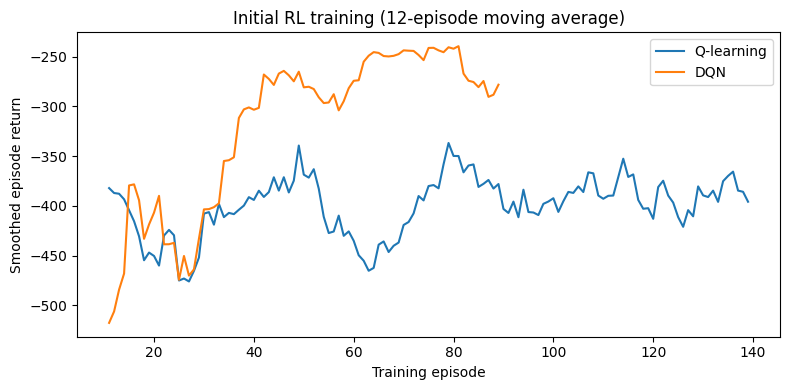

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, curve in [('Q-learning', qcurve), ('DQN', dcurve)]:
    xs = np.arange(len(curve)); window = min(12, len(curve))
    smooth = np.convolve(curve, np.ones(window) / window, mode='valid')
    ax.plot(xs[window - 1:], smooth, label=label)
ax.set(xlabel='Training episode', ylabel='Smoothed episode return',
       title='Initial RL training (12-episode moving average)')
ax.legend(); fig.tight_layout(); fig.savefig(OUT / 'training.png', dpi=155); plt.show()

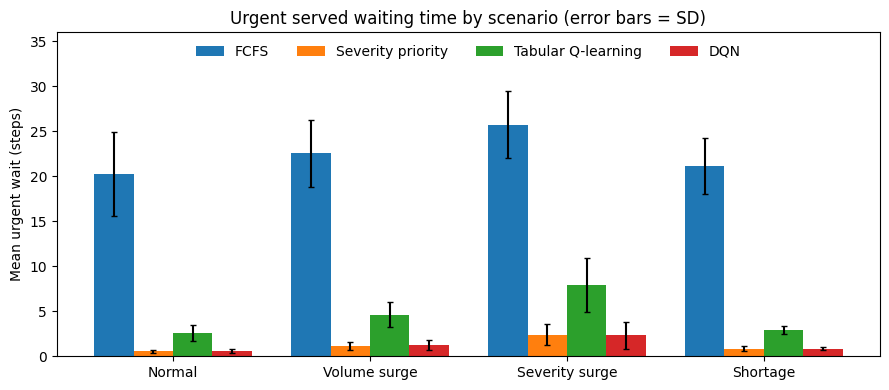

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.2; x = np.arange(len(SCENARIOS))
for i, name in enumerate(policies):
    vals = [[r['mean_urgent_wait_served'] for r in rows if r['scenario'] == sc and r['policy'] == name] for sc in SCENARIOS]
    ax.bar(x + (i - 1.5) * width, [np.mean(v) for v in vals], width, yerr=[np.std(v, ddof=1) for v in vals], capsize=2, label=name)
ax.set_xticks(x, [SCENARIO_NAMES[s] for s in SCENARIOS])
ax.set(ylabel='Mean urgent wait (steps)', title='Urgent served waiting time by scenario (error bars = SD)')
ax.set_ylim(0, 36); ax.legend(ncol=4, loc='upper center', frameon=False); fig.tight_layout(); fig.savefig(OUT / 'urgent_wait.png', dpi=155); plt.show()

One surge shift (seed 101):

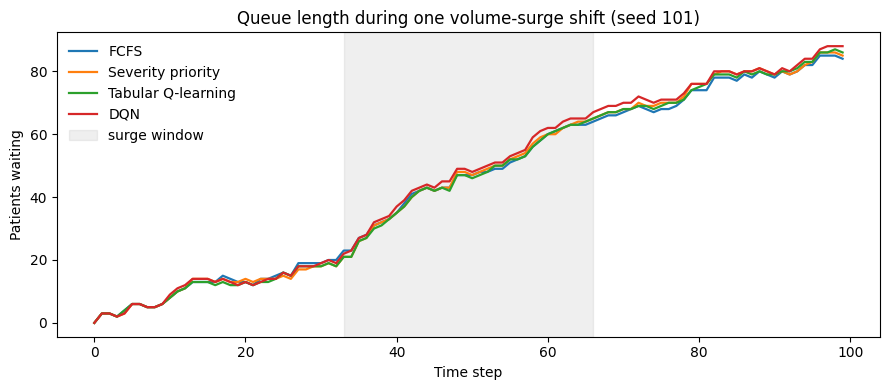

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, policy in policies.items():
    _, hist = run_policy(policy, 'surge', 101)
    ax.plot(hist, label=name, lw=1.6)
ax.axvspan(33, 66, color='grey', alpha=0.12, label='surge window')
ax.set(xlabel='Time step', ylabel='Patients waiting', title='Queue length during one volume-surge shift (seed 101)')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(OUT / 'surge_timeline.png', dpi=155); plt.show()

## Load and backlog
Average queue length barely changes between policies, so we check demand vs capacity and who is left waiting.

In [13]:
mean_service = np.mean(np.arange(2, 6))
print(f'Arrival rate (normal): {RATES.sum():.2f} patients/step')
print(f'Service capacity:      {3 / mean_service:.2f} patients/step (3 resources / {mean_service} mean service steps)')
print(f'Load factor:           {RATES.sum() / (3 / mean_service):.2f}  (>1 means queues grow throughout the episode)\n')

def backlog_by_class(policy, scenario):
    left = np.zeros(4); oldest = []
    for seed in EVAL_SEEDS:
        env = QuickCare(scenario=scenario, seed=seed); obs, _ = env.reset(); done = False
        while not done:
            obs, _, done, _, _ = env.step(policy(env, obs))
        left += [len(qq) for qq in env.queues]
        oldest.append(max((env.t - qq[0][0]) for qq in env.queues if qq))
    return left / len(EVAL_SEEDS), np.mean(oldest)

print(f"{'Scenario':<15}{'Policy':<20}" + ''.join(f'{s:>10}' for s in SEVERITY) + f"{'Oldest wait':>13}")
for sc in ['normal', 'surge']:
    for name, policy in policies.items():
        left, oldest = backlog_by_class(policy, sc)
        print(f'{SCENARIO_NAMES[sc]:<15}{name:<20}' + ''.join(f'{v:>10.1f}' for v in left) + f'{oldest:>13.1f}')

Arrival rate (normal): 1.36 patients/step
Service capacity:      0.86 patients/step (3 resources / 3.5 mean service steps)
Load factor:           1.59  (>1 means queues grow throughout the episode)

Scenario       Policy                critical    urgent  moderate       low  Oldest wait
Normal         FCFS                       5.6       7.6      16.2      24.0         40.4
Normal         Severity priority          0.2       0.0       3.2      49.4         80.0
Normal         Tabular Q-learning         0.2       2.8      10.6      40.2         61.6
Normal         DQN                        0.2       0.0      25.6      28.0         63.8
Volume surge   FCFS                       6.4      13.8      27.6      44.2         53.6
Volume surge   Severity priority          0.0       0.2      17.6      75.0         89.6
Volume surge   Tabular Q-learning         0.0       2.2      23.2      66.2         73.2
Volume surge   DQN                        0.0       0.2      40.4      52.8         72.8


Share of started patients by class (normal scenario):

In [14]:
def action_share(policy, scenario='normal'):
    counts = np.zeros(4)
    for seed in EVAL_SEEDS:
        env = QuickCare(scenario=scenario, seed=seed); obs, _ = env.reset(); done = False
        while not done:
            a = policy(env, obs)
            if a in env.valid_actions():
                counts[a] += 1
            obs, _, done, _, _ = env.step(a)
    return 100 * counts / counts.sum()

print(f"{'Policy':<20}" + ''.join(f'{s:>10}' for s in SEVERITY) + '   (% of patients started)')
for name, policy in policies.items():
    print(f'{name:<20}' + ''.join(f'{v:>9.1f}%' for v in action_share(policy)))

Policy                critical    urgent  moderate       low   (% of patients started)
FCFS                      6.4%     13.3%     32.1%     48.2%
Severity priority        13.2%     22.9%     48.3%     15.5%
Tabular Q-learning       13.4%     19.6%     39.4%     27.6%
DQN                      13.4%     23.2%     20.1%     43.3%


## Notes
- Severity priority has the lowest urgent wait in normal and volume surge. DQN is close everywhere (0.61 vs 0.55 normal), ties it in the shortage and is slightly lower in the severity surge (2.34 vs 2.39).
- DQN beats tabular Q-learning in every scenario. In about 28% of evaluation decisions the tabular agent picks an action it never tried in training (default value 0), so part of its behaviour is just a fallback to the most urgent queue.
- After critical/urgent, DQN serves low before moderate, even though the reward weights moderate higher.
- Load factor is 1.59, so queues grow in every scenario and the policies only change who waits.
- Severity priority leaves ~49 low-urgency patients waiting at the end of a normal shift. Served-wait averages don't show this.

Next: Double DQN, recalibrated arrival rates, multiple starts per step, longer training and more seeds.

## References
1. Sutton and Barto, *Reinforcement Learning: An Introduction*, 2nd ed., 2018.
2. Mnih et al., Human-level control through deep reinforcement learning, *Nature*, 2015.
3. van Hasselt, Guez and Silver, Deep Reinforcement Learning with Double Q-learning, *AAAI*, 2016.
4. Morley et al., Emergency department crowding: a systematic review, *PLOS ONE*, 2018.